In [54]:
%pip install pandas numpy matplotlib seaborn datasets nltk Sastrawi scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
import nltk
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

print("Semua library berhasil diimpor!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Semua library berhasil diimpor!
Pandas: 3.0.3
NumPy: 2.4.6


In [3]:
from datasets import load_dataset

dataset = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")

print(dataset)


DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


In [4]:
import pandas as pd

# Mengubah dataset menjadi DataFrame
df = dataset["train"].to_pandas()

# Menampilkan 5 data pertama
print("5 DATA PERTAMA:")
display(df.head())

# Menampilkan informasi dataset
print("\nINFORMASI DATASET:")
print("Jumlah seluruh data:", len(df))
print("Nama kolom:", df.columns.tolist())

print("\nINFORMASI TIPE DATA:")
df.info()

5 DATA PERTAMA:


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0



INFORMASI DATASET:
Jumlah seluruh data: 11606
Nama kolom: ['review', 'translate', 'sentimen']

INFORMASI TIPE DATA:
<class 'pandas.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     11606 non-null  str  
 1   translate  11606 non-null  str  
 2   sentimen   11606 non-null  int64
dtypes: int64(1), str(2)
memory usage: 2.6 MB


In [5]:
# Menghitung jumlah masing-masing sentimen
jumlah_sentimen = df["sentimen"].value_counts().sort_index()

print("DISTRIBUSI SENTIMEN")
print("===================")

for label, jumlah in jumlah_sentimen.items():
    nama = "Negatif" if label == 0 else "Positif"
    print(f"{nama}: {jumlah} ulasan")

# Menampilkan persentase sentimen
print("\nPERSENTASE SENTIMEN")
print("===================")

persentase = df["sentimen"].value_counts(normalize=True).sort_index() * 100

for label, nilai in persentase.items():
    nama = "Negatif" if label == 0 else "Positif"
    print(f"{nama}: {nilai:.2f}%")

DISTRIBUSI SENTIMEN
Negatif: 5803 ulasan
Positif: 5803 ulasan

PERSENTASE SENTIMEN
Negatif: 50.00%
Positif: 50.00%


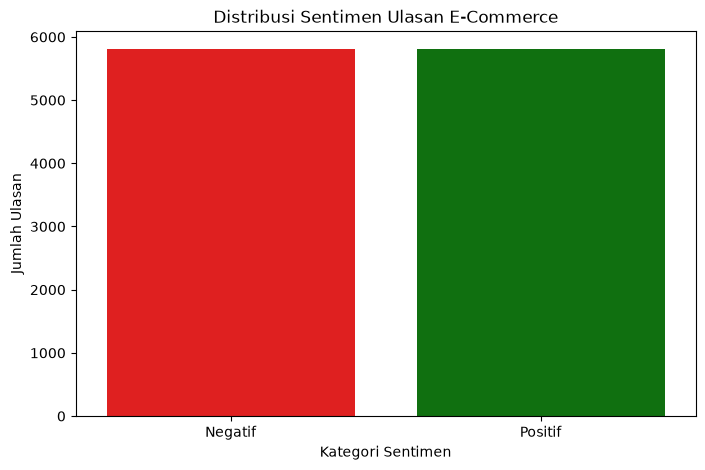

In [6]:
# Membuat grafik distribusi sentimen
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentimen",
    hue="sentimen",
    palette={0: "red", 1: "green"},
    legend=False
)

plt.title("Distribusi Sentimen Ulasan E-Commerce")
plt.xlabel("Kategori Sentimen")
plt.ylabel("Jumlah Ulasan")
plt.xticks([0, 1], ["Negatif", "Positif"])

plt.show()

In [7]:
import re
import string
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Download data NLTK
nltk.download('punkt_tab')
nltk.download('stopwords')

# Membuat stemmer bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Mengambil stopword bahasa Indonesia
stop_words = set(stopwords.words('indonesian'))

print("Persiapan preprocessing berhasil!")

Persiapan preprocessing berhasil!


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [10]:
from functools import lru_cache

@lru_cache(maxsize=None)
def stem_kata(kata):
    return stemmer.stem(kata)

def preprocessing(teks):
    # 1. Case folding
    teks = teks.lower()

    # 2. Cleaning
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'\d+', '', teks)
    teks = teks.translate(str.maketrans('', '', string.punctuation))
    teks = re.sub(r'[^a-zA-Z\s]', '', teks)

    # 3. Tokenisasi
    tokens = word_tokenize(teks)

    # 4. Stopword removal
    tokens = [kata for kata in tokens if kata not in stop_words]

    # 5. Stemming
    tokens = [stem_kata(kata) for kata in tokens]

    return ' '.join(tokens)

print("Fungsi preprocessing berhasil dibuat!")

Fungsi preprocessing berhasil dibuat!


In [11]:
import time

waktu_mulai = time.time()

df["review_preprocessing"] = df["review"].apply(preprocessing)

waktu_selesai = time.time()

print("Preprocessing seluruh dataset berhasil!")
print("Jumlah data yang diproses:", len(df))
print("Waktu proses:", round(waktu_selesai - waktu_mulai, 2), "detik")

display(df[["review", "review_preprocessing"]].head())

Preprocessing seluruh dataset berhasil!
Jumlah data yang diproses: 11606
Waktu proses: 1223.76 detik


,review,review_preprocessing
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,suara mic puas pesan yg nyala sy pasti lg klik...
1,Good. Mudah-mudahan awet. Makasih,good mudahmudahan awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati
3,Kualitas produk baik. Harga terjangkau dan pen...,kualitas produk harga jangkau kirim cepet bang...
4,"Overall bagus, tombol berfungsi semuanya, tapi...",overall bagus tombol fungsi packaging penyot r...


In [13]:
hasil_10 = df[["review", "review_preprocessing"]].head(10).copy()

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_columns", None)

display(hasil_10.style.set_properties(**{
    "text-align": "left",
    "white-space": "normal",
    "max-width": "350px"
}))

,review,review_preprocessing
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudahmudahan awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek tolong perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,kualitas produk harga jangkau kirim cepet banget udh x order oke tp sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi packaging penyot robek
5,"Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.",produk original kualitas cepat kirim sanagt cepat recommended seller
6,kualitas sangat jelek. bocor,kualitas jelek bocor
7,"terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka",terimakasih ka ya barang terima sukses ka
8,"Body nya lebih berat dari cm 1579, spiral nya lebih tipis dibanding cm 1579, semoga awet, beli CM 1659 penasaran Aja, yang cm 1579 udah mau rusak mesin nya, Harga lebih murah 4k dari cm 1579 Fast delivery, courier Ramah sangat, ty seller",body nya berat cm spiral nya tipis banding cm moga awet beli cm penasaran aja cm udah rusak mesin nya harga murah k cm fast delivery courier ramah ty seller
9,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 dan ternyata tab SKETSA ADVAN tidak bisa di nyalakan sama sekali dan di cas juga posisi Tab tidak bisa menyala,pesan terima tanggal january buka pagi tanggal january tab sketsa advan nyala cas posisi tab nyala
